In [1]:
suppressMessages(library(Seurat))
suppressMessages(library(Signac))
suppressMessages(library(dplyr))
suppressMessages(library(ggplot2))
suppressMessages(library(future))
suppressMessages(library(parallel))
suppressMessages(library(RColorBrewer))
suppressMessages(library(viridis))
suppressMessages(library(qs))
suppressMessages(library(harmony))
suppressMessages(library(igraph))
suppressMessages(library(ggraph))
suppressMessages(library(ggrepel)) 
library(tidyr)
library(foreach)
library(doParallel)
library(tidygraph)
library(anndata)
library(randomForest)
library(pheatmap)
library(dbscan)
library(scDblFinder)
library(Matrix)

suppressMessages(library(cowplot))
# Python 环境
suppressMessages(library(reticulate))
RETICULATE_PYTHON <- "/home/chaiqw/project/mb/.venv/bin/python"
use_virtualenv("/home/chaiqw/project/mb/.venv")

Sys.setenv(
  http_proxy  = "http://10.10.50.114:45698",
  https_proxy = "http://10.10.50.114:45698"
)


# 资源设定
plan("multicore", workers = 64)
options(future.globals.maxSize = 100000 * 1024^5)



载入程序包：‘tidyr’


The following object is masked from ‘package:igraph’:

    crossing


载入需要的程序包：iterators


载入程序包：‘tidygraph’


The following object is masked from ‘package:igraph’:

    groups


The following object is masked from ‘package:stats’:

    filter



载入程序包：‘anndata’


The following object is masked from ‘package:SeuratObject’:

    Layers


randomForest 4.7-1.2

Type rfNews() to see new features/changes/bug fixes.


载入程序包：‘randomForest’


The following object is masked from ‘package:ggplot2’:

    margin


The following object is masked from ‘package:dplyr’:

    combine



载入程序包：‘dbscan’


The following object is masked from ‘package:stats’:

    as.dendrogram


载入需要的程序包：SingleCellExperiment

载入需要的程序包：SummarizedExperiment

载入需要的程序包：MatrixGenerics

载入需要的程序包：matrixStats


载入程序包：‘matrixStats’


The following object is masked from ‘package:dplyr’:

    count



载入程序包：‘MatrixGenerics’


The following objects are masked from ‘package:matrixStats’:

    colAlls, colAnyNAs, colAn

In [ ]:
mouse1 = readRDS('/mnt/90-connectome/Personal/CQW/midbrain/datasets/GSE271781_WT_seurat.rds')
mouse1 = JoinLayers(mouse1)
mouse1

In [3]:
# 直接将基因名转为大写，不进行同源基因表映射；重名基因的 counts 求和。
mouse_counts <- GetAssayData(mouse1, assay = "RNA", layer = "counts")

feature_names <- rownames(mouse_counts)
new_symbols <- toupper(feature_names)

symbol_levels <- unique(new_symbols)
feature_aggregation <- Matrix::sparseMatrix(
  i = match(new_symbols, symbol_levels),
  j = seq_along(new_symbols),
  x = 1,
  dims = c(length(symbol_levels), length(new_symbols))
)
uppercase_counts <- feature_aggregation %*% mouse_counts
rownames(uppercase_counts) <- symbol_levels
colnames(uppercase_counts) <- colnames(mouse_counts)

mouse1_metadata <- mouse1[[]]
mouse1_project <- Project(mouse1)
mouse1 <- CreateSeuratObject(
  counts = uppercase_counts,
  meta.data = mouse1_metadata,
  project = mouse1_project
)

message(
  sum(feature_names != new_symbols), " 个基因名转为大写；",
  length(new_symbols) - length(symbol_levels), " 个重名条目合并；",
  length(symbol_levels), " 个基因保留。"
)

31933 个基因名转为大写；0 个重名条目合并；32285 个基因保留。



In [3]:
mouse1$Animal = mouse1$sample_id
mouse1$sample = mouse1$sample_id
mouse1$source = 'published_datasets'



In [7]:
Idents(mouse1) = ""
mouse1_sub = subset(mouse1, downsample = 3461)
mouse1_sub

An object of class Seurat 
32285 features across 3461 samples within 1 assay 
Active assay: RNA (32285 features, 0 variable features)
 1 layer present: counts

Normalizing layer: counts

Finding variable features for layer counts

Centering and scaling data matrix

Computing nearest neighbor graph

Computing SNN

Warning message:
“UNRELIABLE VALUE: One of the ‘future.apply’ iterations (‘future_lapply-1’) unexpectedly generated random numbers without declaring so. There is a risk that those random numbers are not statistically sound and the overall results might be invalid. To fix this, specify 'future.seed=TRUE'. This ensures that proper, parallel-safe random numbers are produced via a parallel RNG method. To disable this check, use 'future.seed = NULL', or set option 'future.rng.onMisuse' to "ignore".”
Transposing data matrix

Initializing state using k-means centroids initialization

Harmony 1/10

Harmony 2/10

Harmony 3/10

Harmony converged after 3 iterations

Computing nearest neighbor graph

Computing SNN

Warning message:
“UNRELIABLE VALUE: One of the ‘future.apply’ iterations (‘future_lapply-1’) unexpectedly generated random numbers w

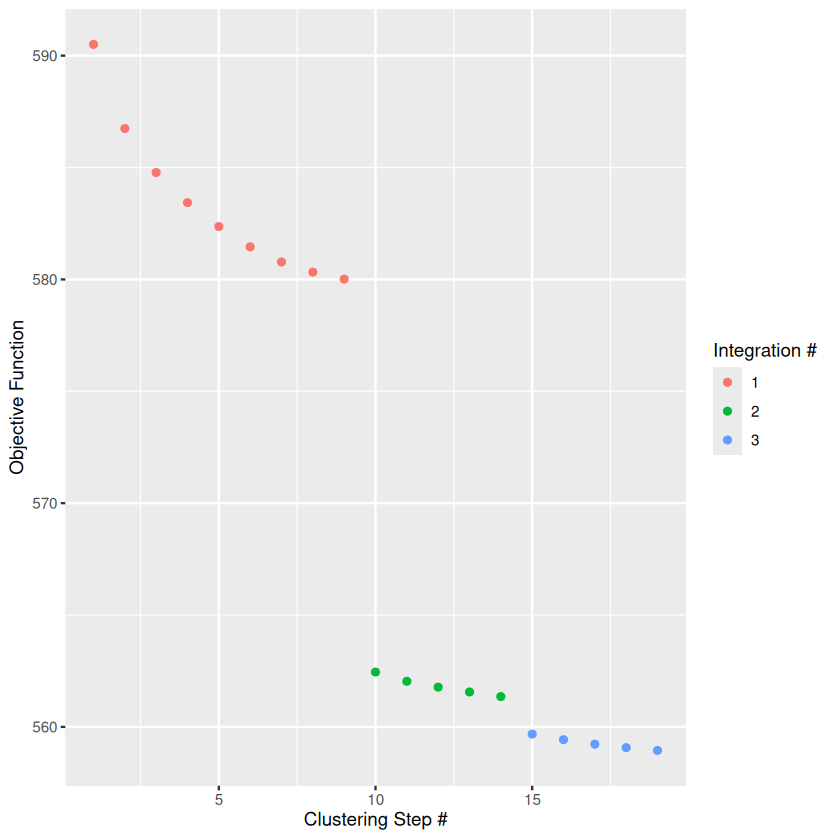

In [ ]:
class_resolution = 0.2

mouse$Animal = mouse$sample_id
Idents(mouse) = ""
mouse1_sub = subset(mouse, downsample = 3461)
# mouse1_sub = mouse1

mt_gene = c("ND6", "COX3", "COX1", "ND5", "ND4", "ND2", "ND4L", "ATP8", "CYTB", "COX2", "ND3", "ATP6", "ND1")

assay = mouse1_sub@assays$RNA$counts
meta = mouse1_sub@meta.data
new_assay = assay[setdiff(rownames(assay), mt_gene), ]

mouse1_sub = CreateSeuratObject(counts = new_assay)
mouse1_sub = AddMetaData(mouse1_sub, meta)

mouse1_sub_1 = NormalizeData(mouse1_sub, normalization.method = "LogNormalize", scale.factor = 10000)
mouse1_sub_1 = FindVariableFeatures(mouse1_sub_1, selection.method = "vst", nfeatures = 3000)
mouse1_sub_1 = ScaleData(mouse1_sub_1, features = rownames(mouse1_sub_1))

# mouse_1 = SCTransform(mouse1_sub, verbose = FALSE,  vst.flavor = "v2",vars.to.regress = "nCount_RNA")

mouse_2 = mouse1_sub_1 %>%
    RunPCA(npcs = 50, verbose = FALSE) %>%
    FindNeighbors(dims = 1:25) %>%
    FindClusters(verbose = FALSE, resolution = class_resolution, random.seed = 1234) %>%
    RunUMAP(dims = 1:25, umap.method = "umap-learn")

mouse_3 = RunHarmony(
    mouse_2, group.by.vars = "Animal", plot_convergence = TRUE,
    reduction.save = "harmony", dims.use = 1:25,
    theta = 2
)

mouse_4 = mouse_3 %>%
    FindNeighbors(reduction = "harmony", dims = 1:25) %>%
    FindClusters(verbose = FALSE, resolution = class_resolution, random.seed = 1234) %>%
    RunUMAP(reduction = "harmony", dims = 1:25)

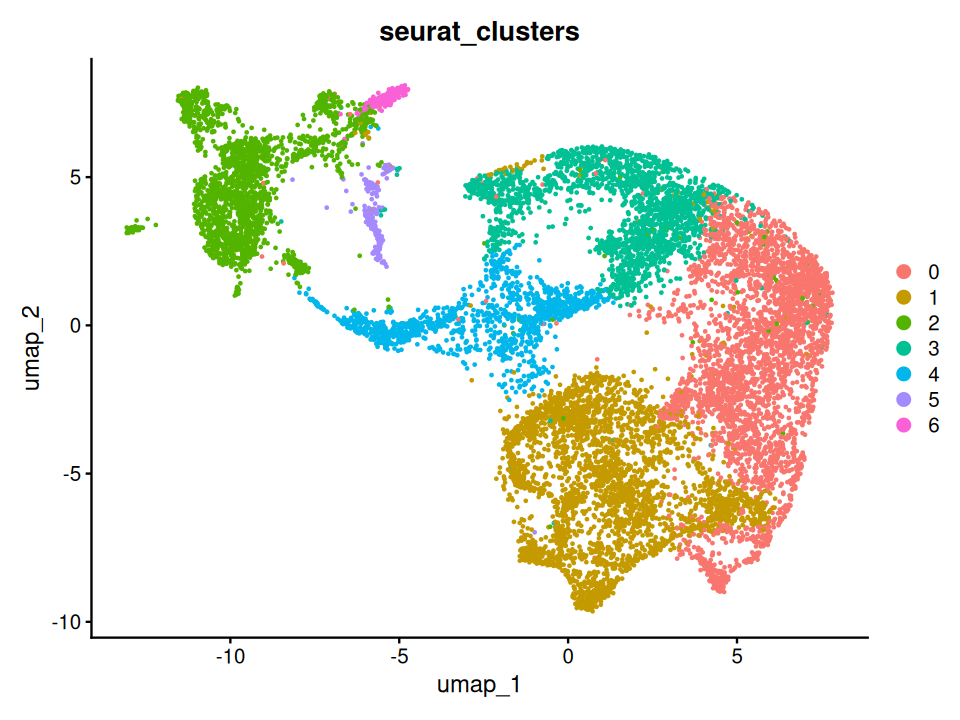

In [11]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(mouse_4,group.by = "seurat_clusters")

In [10]:
class_resolution = 0.1
mouse_4 = mouse_3 %>%
    FindNeighbors(reduction = "harmony", dims = 1:25) %>%
    FindClusters(verbose = FALSE, resolution = class_resolution, random.seed = 1234) %>%
    RunUMAP(reduction = "harmony", dims = 1:25)

Computing nearest neighbor graph

Computing SNN

Warning message:
“UNRELIABLE VALUE: One of the ‘future.apply’ iterations (‘future_lapply-1’) unexpectedly generated random numbers without declaring so. There is a risk that those random numbers are not statistically sound and the overall results might be invalid. To fix this, specify 'future.seed=TRUE'. This ensures that proper, parallel-safe random numbers are produced via a parallel RNG method. To disable this check, use 'future.seed = NULL', or set option 'future.rng.onMisuse' to "ignore".”
16:15:37 UMAP embedding parameters a = 0.9922 b = 1.112

16:15:37 Read 12951 rows and found 25 numeric columns

16:15:37 Using Annoy for neighbor search, n_neighbors = 30

16:15:37 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

1

In [12]:
mouse_4$species = "mouse"
mouse_4$cluster = paste0("DA_", mouse_4$seurat_clusters)
mouse_4$Cluster = paste0("mouse_DA_", mouse_4$seurat_clusters)

In [35]:
class_resolution = 0.2
mouse_4 = mouse_3 %>%
    FindNeighbors(reduction = "harmony", dims = 1:25) %>%
    FindClusters(verbose = FALSE, resolution = class_resolution, random.seed = 1234) %>%
    RunUMAP(reduction = "harmony", dims = 1:25)

Computing nearest neighbor graph

Computing SNN

Warning message:
“UNRELIABLE VALUE: One of the ‘future.apply’ iterations (‘future_lapply-1’) unexpectedly generated random numbers without declaring so. There is a risk that those random numbers are not statistically sound and the overall results might be invalid. To fix this, specify 'future.seed=TRUE'. This ensures that proper, parallel-safe random numbers are produced via a parallel RNG method. To disable this check, use 'future.seed = NULL', or set option 'future.rng.onMisuse' to "ignore".”
16:10:32 UMAP embedding parameters a = 0.9922 b = 1.112

16:10:32 Read 3461 rows and found 25 numeric columns

16:10:32 Using Annoy for neighbor search, n_neighbors = 30

16:10:32 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

16

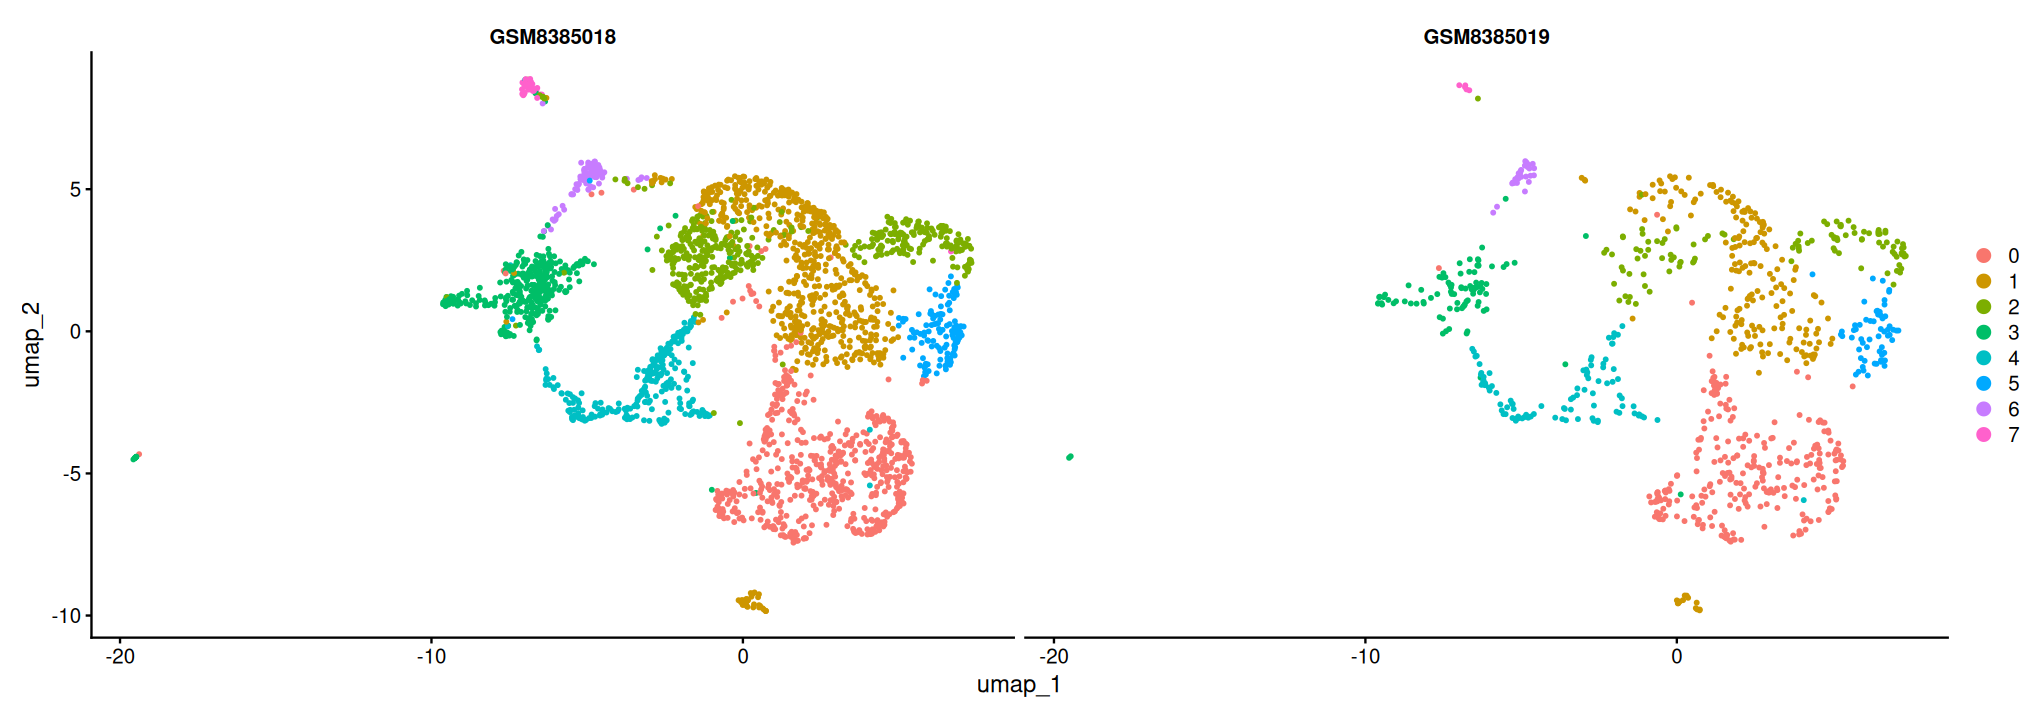

In [36]:
options(repr.plot.width = 17, repr.plot.height = 6)
DimPlot(mouse_4,split.by = "Animal")

In [9]:
seurat2  = readRDS('/mnt/90-connectome/Personal/CQW/midbrain/area_h5ad/20260807_VTA_DA_seurat_cluster.rds')


In [37]:
mouse_4$species = "mouse"
mouse_4$cluster = paste0("DA_", mouse_4$seurat_clusters)
mouse_4$Cluster = paste0("mouse_DA_", mouse_4$seurat_clusters)

seurat2$species = "macaque"
seurat2$sample = seurat2$Library
seurat2$Cluster = paste0("macaque_", seurat2$cluster)

In [39]:
seurat_list <- list(mouse = mouse_4, mq = seurat2)
original = merge(mouse_4, seurat2)
original

An object of class Seurat 
58800 features across 6922 samples within 2 assays 
Active assay: SCT (20233 features, 3000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: RNA

In [40]:
original = JoinLayers(original,assay = 'RNA')

In [41]:
assay = original@assays$RNA$counts
meta = original@meta.data
new_assay = assay[setdiff(rownames(assay), mt_gene), ]

original = CreateSeuratObject(counts = new_assay)
original = AddMetaData(original, meta)

In [42]:
# original 为平衡细胞数后合并的 mouse + macaque 对象
objects <- SplitObject(original, split.by = "sample")

objects <- lapply(objects, function(x) {
  DefaultAssay(x) <- "RNA"
  x <- NormalizeData(x, verbose = FALSE)
  FindVariableFeatures(x, nfeatures = 3000, verbose = FALSE)
})

features <- SelectIntegrationFeatures(objects, nfeatures = 2000)

anchors <- FindIntegrationAnchors(
  object.list = objects,
  normalization.method = "LogNormalize",
  reduction = "cca",
  anchor.features = features,
  dims = 1:20,
  k.anchor = 5
)

integrated <- IntegrateData(
  anchorset = anchors,
  normalization.method = "LogNormalize",
  dims = 1:20,
  k.weight = 50
)


Scaling features for provided objects

Finding all pairwise anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 3317 anchors

Filtering anchors

	Retained 3226 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 1433 anchors

Filtering anchors

	Retained 1281 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 1399 anchors

Filtering anchors

	Retained 1234 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 1541 anchors

Filtering anchors

	Retained 1392 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 1489 anchors

Filtering anchors

	Retained 1299 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 1049 anchors

Filtering anchors

	Retained 1036 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 1854 anchors

Filtering anchors

	Retained 1575 an

In [43]:
DefaultAssay(integrated) <- "integrated"
integrated <- ScaleData(integrated)
integrated <- RunPCA(integrated, npcs = 30, seed.use = 1234)
integrated <- RunUMAP(integrated, dims = 1:20, seed.use = 1234)

Centering and scaling data matrix

PC_ 1 
Positive:  ENSMFAG00000032199, ALDOC, SNCG, ENSMFAG00000043121, UBL5, NEFM, PRR5L, ENSMFAG00000007184, RPL23, COX6A1 
	   ACTB, ENSMFAG00000032800, CD63, ENSMFAG00000036310, NEFL, GFAP, ENSMFAG00000032173, ATP6V0C, ENSMFAG00000035836, ENSMFAG00000046193 
	   YWHAB, CD99, ENSMFAG00000002773, ENSMFAG00000033843, PLP1, GAPDH, NDUFA1, ENSMFAG00000039146, NPTX2, ENSMFAG00000039531 
Negative:  ABCA8, KIAA1755, SLC5A11, C21orf91, OPALIN, C10orf90, ENSMFAG00000035765, HHIP, ENSMFAG00000041985, ITGA2 
	   ENSMFAG00000043430, CHST3, ZNF536, ZNF608, ENSMFAG00000044069, P3H2, ELAVL4, KCND3, KIF25, SHROOM4 
	   GALNTL6, PPP2R2B, GPR37, SCD, AUTS2, GLDN, MAN2A1, COL4A5, DOCK4, PLCB4 
PC_ 2 
Positive:  SORCS3, KCNH7, TNIK, GRID2, KCND2, GRIK2, PDE8B, GRM8, TENM3, NAV3 
	   NDST3, RYR2, KCNIP1, THSD7B, KCNH5, TRPM3, EPB41L3, KCNN2, NEGR1, KCNAB1 
	   PLPP4, PARD3B, UNC13C, FRMD5, PLPPR1, PHACTR1, UNC5D, PCDH7, TMCC3, HS6ST2 
Negative:  ADAMTSL1, NWD2, COL25A1,

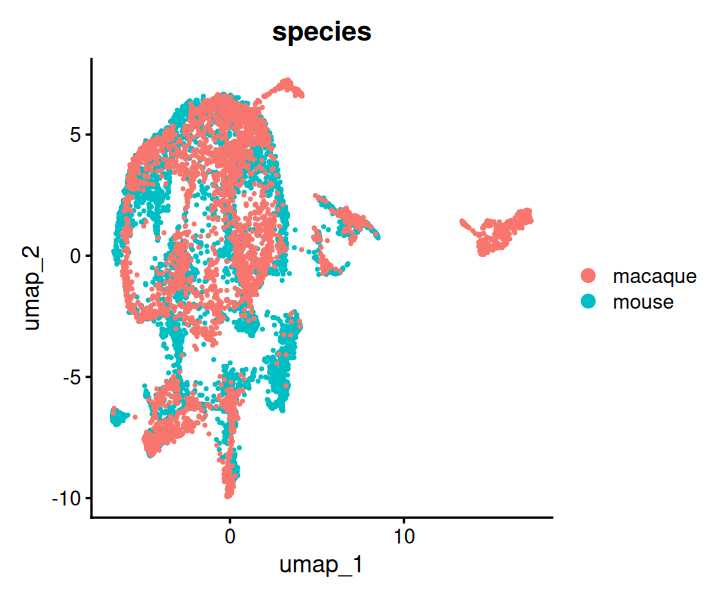

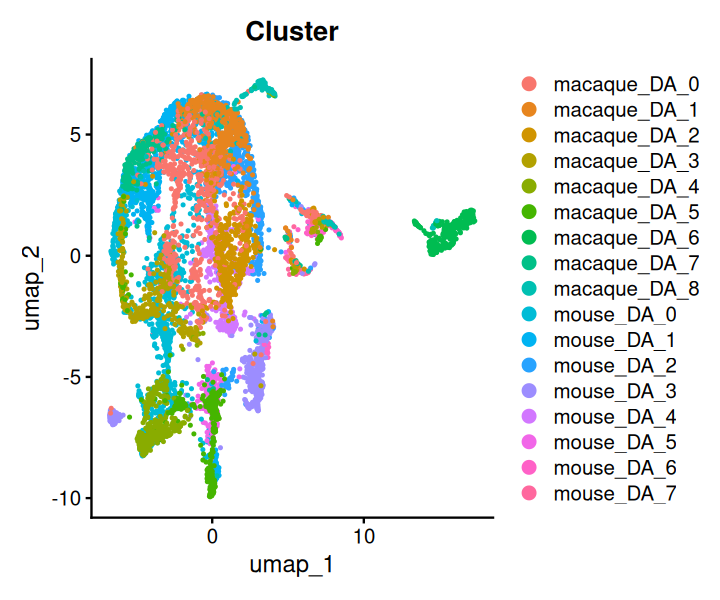

In [47]:
options(repr.plot.width = 6, repr.plot.height = 5)

DimPlot(integrated, reduction = "umap", group.by = "species")
DimPlot(integrated, reduction = "umap", group.by = "Cluster")

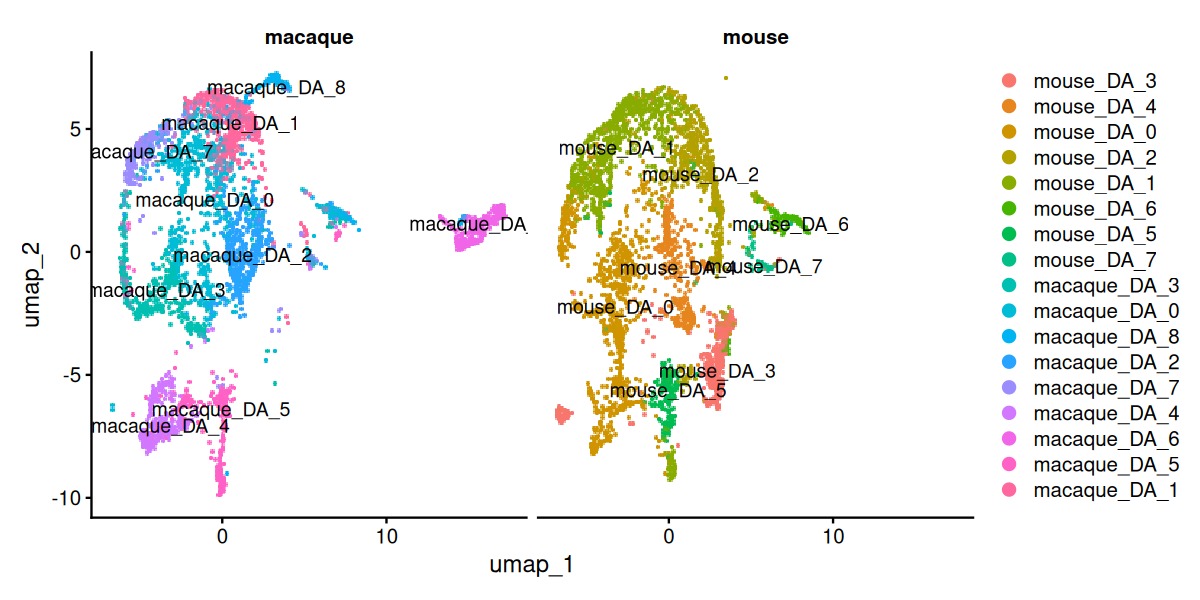

In [3]:
options(repr.plot.width = 10, repr.plot.height = 5)
Idents(integrated) <- "Cluster"

# DimPlot(integrated, reduction = "umap", split.by = "species",label = T)

DimPlot(
    integrated, 
    reduction = "umap", 
    split.by = "species",
    label = T,
      raster = TRUE,
  raster.dpi = c(300, 300),
  pt.size = 2
    )

In [4]:
pdf(
  "/mnt/90-connectome/Personal/CQW/midbrain/figure/DA_macaque_vs_mouse_umap-5.pdf",
  width = 10,
  height = 5,
  useDingbats = FALSE
)
integrated$species <- factor(
    integrated$species,
    levels = c("mouse", "macaque")
)
options(repr.plot.width = 10, repr.plot.height = 5)
Idents(integrated) <- "Cluster"

DimPlot(
    integrated, 
    reduction = "umap", 
    split.by = "species",
    label = T,
      raster = TRUE,
  raster.dpi = c(300, 300),
   pt.size = 2
    )

dev.off()

agg_record_1469767867 
                    2

In [50]:
integrated = integrated %>%
    FindNeighbors(dims = 1:20) %>%
    FindClusters(verbose = FALSE, resolution = 1, random.seed = 1234)

Computing nearest neighbor graph



Computing SNN

Warning message:
“UNRELIABLE VALUE: One of the ‘future.apply’ iterations (‘future_lapply-1’) unexpectedly generated random numbers without declaring so. There is a risk that those random numbers are not statistically sound and the overall results might be invalid. To fix this, specify 'future.seed=TRUE'. This ensures that proper, parallel-safe random numbers are produced via a parallel RNG method. To disable this check, use 'future.seed = NULL', or set option 'future.rng.onMisuse' to "ignore".”


In [ ]:
saveRDS(integrated, "/mnt/90-connectome/Personal/CQW/midbrain/datasets/DA_Macaque_Elife_Mouse_inte.rds")

In [2]:
integrated = readRDS("/mnt/90-connectome/Personal/CQW/midbrain/datasets/DA_Macaque_Elife_Mouse_inte.rds")

`summarise()` has grouped output by 'term'. You can override using the
`.groups` argument.


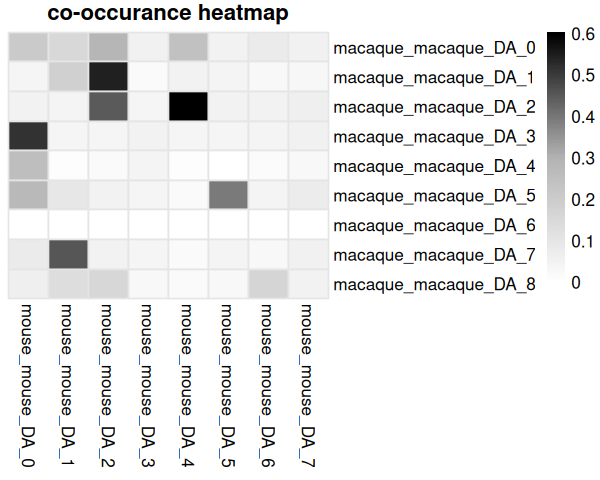

In [51]:
GetCoCurMatrix <- function(x.tbl, tech.var = NULL){
    ratio_matrix <- x.tbl %>% setNames(c('species','Cluster','seurat_clusters')) %>% mutate_if(is.factor, as.character) %>% 
        tidyr::unite(col = "term", c('species','Cluster'),sep = '_') %>% group_by(term, seurat_clusters) %>%
        summarise(cell.num = dplyr::n()) %>% group_by(term) %>% mutate(ratio = cell.num/sum(cell.num)) %>% ungroup() %>% 
        select(-cell.num) %>% tidyr::pivot_wider(names_from = term,values_from = ratio, values_fill = 0) %>% 
        select(-seurat_clusters)
    
    x <- grep(paste0(tech.var[1],"_"),colnames(ratio_matrix),value = T)
    y <- grep(paste0(tech.var[2],"_"),colnames(ratio_matrix),value = T)
    
    co_cluster_matrix <- expand.grid(x, y) %>% 
        mutate(overlapScore = apply(.,1,FUN = function(i){
            sum(pmin(ratio_matrix[[i[[1]]]], ratio_matrix[[i[[2]]]]))
        })) %>% 
        tidyr::pivot_wider(names_from = "Var2", values_from = "overlapScore", values_fill = 0) %>% 
        tibble::column_to_rownames('Var1')
    
    return(co_cluster_matrix)
}

cocls.tbl1 <- integrated %>% FetchData(., vars = c('species','Cluster','seurat_clusters')) 
cocur.obs1 <- GetCoCurMatrix(x.tbl = cocls.tbl1, tech.var = c('mouse','macaque'))


GetCoCurRand <- function(x.tbl, tech.var = NULL, ech = 1e+3, cocur.obs1){
    x.tbl <- x.tbl %>% setNames(c('species','Cluster','seurat_clusters')) %>% mutate_if(is.factor, as.character)
    pbapply::pblapply(1:ech, function(._){
        lapply(unique(x.tbl$species), function(.x){
            .sub <- x.tbl %>% filter(species == .x)
            mapping <- setNames(unique(.sub$seurat_clusters), sample(unique(.sub$seurat_clusters)))
            .sub <- .sub %>% mutate(seurat_clusters = recode(seurat_clusters, !!!mapping))
            {### 添加模拟噪音
                noise_index <- .sub %>% sample_frac(0.1) %>% row.names(.)
                .sub <- .sub %>% mutate(Cluster = if_else(row.names(.) %in% noise_index, sample(Cluster),Cluster))
            }
            return(.sub)
        }) %>% bind_rows() -> shuffle_
        cocur.rand <- GetCoCurMatrix(x.tbl = shuffle_, tech.var = tech.var)
        cocur.rand <- cocur.rand[rownames(cocur.obs1),colnames(cocur.obs1)]
        return(cocur.rand)
    }) %>% suppressMessages()
}

cocur.rnd <- GetCoCurRand(x.tbl = cocls.tbl1, tech.var = c('mouse','macaque'), cocur.obs1 = cocur.obs1)
p_values <- matrix(NA, nrow = nrow(cocur.obs1), ncol = ncol(cocur.obs1))
dimnames(p_values) <- list(rownames(cocur.obs1),colnames(cocur.obs1))
for (i in 1:nrow(cocur.obs1)) {
    for (j in 1:ncol(cocur.obs1)) {
        observed_value <- cocur.obs1[i, j]
        randomized_values <- purrr::map_dbl(cocur.rnd, ~ .x[i, j])
        test_result <- wilcox.test(randomized_values,mu = observed_value, alternative = "less", exact = F)
        p_values[i, j] <- test_result$p.value
    }
}
p_sign <- symnum(as.matrix(p_values), corr = FALSE, na = FALSE, 
                 cutpoints = c(0, 0.001, 0.01, 0.05, 0.1, 1), 
                 symbols = c("***", "**", "*", ".#", " "))


cocur.obs1_rename = cocur.obs1

# rownames(cocur.obs1_rename) <- gsub("^rat_", "", rownames(cocur.obs1_rename))
# colnames(cocur.obs1_rename) <- gsub("^macaque_", "", colnames(cocur.obs1_rename))

options(repr.plot.width = 5, repr.plot.height = 4)
{ ### 展示 OverlapRatio并保存热图
    pheatmap::pheatmap(
        t(cocur.obs1_rename), 
        main = "co-occurance heatmap", 
        border_color = "grey90",
        cluster_rows = F,
        cluster_cols = F,
        max = 0.6,
        min = 0,
        color = colorRampPalette(c("white", "grey70", "black"))(100),
        # filename = "/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/EX_cellpaper_motor_co_heatmap_subclass.pdf", # 保存为PDF文件
        width = 5, height = 4
    )
}

In [52]:
rownames(cocur.obs1_rename) <- sub(
  "^(mouse|macaque)_\\1_", "\\1_", rownames(cocur.obs1_rename)
)

colnames(cocur.obs1_rename) <- sub(
  "^(mouse|macaque)_\\1_", "\\1_", colnames(cocur.obs1_rename)
)

In [54]:
options(repr.plot.width = 5, repr.plot.height = 4)
{ ### 展示 OverlapRatio并保存热图
    pheatmap::pheatmap(
        t(cocur.obs1_rename), 
        main = "co-occurance heatmap", 
        border_color = "grey90",
        cluster_rows = F,
        cluster_cols = F,
        color = colorRampPalette(c("white", "grey70", "black"))(100),
        filename = "/mnt/90-connectome/Personal/CQW/midbrain/figure/DA_macaque_vs_mouse_elife-4.pdf", # 保存为PDF文件
        width = 5, height = 4,
        breaks = seq(0, 0.6, length.out = 101)
    )
}